# Лабораторная работа 2

## Линейная регрессия

### Задание 1. Метод наименьших квадратов (3 балла)

Скачайте файлы ``train.txt`` и ``test.txt``. В первом из них находится обучающая выборка, а во втором — тестовая. Каждый из файлов содержит два столбца чисел, разделённых пробелами: в первом — $n$ точек (значения аргумента $x$), во втором — значения некоторой функции $y = f(x)$ в этих точках, искажённые случайным шумом. Ваша задача — по обучающей выборке подобрать функцию $y = g(x)$, пристойно приближающую неизвестную вам зависимость.

In [18]:
import numpy

data_train = numpy.loadtxt('/content/train.txt', delimiter=',')
data_test = numpy.loadtxt('/content/test.txt', delimiter=',')


**0. [0 баллов]** Разделим значения $x$ и $y$:

In [ ]:
X_train = data_train[:, 0]
Y_train = data_train[:, 1]

X_test = data_test[:, 0]
Y_test = data_test[:, 1]

**1. [0.1 балла]** Найдите с помощью метода наименьших квадратов линейную функцию ($y = kx + b$), наилучшим образом приближающую неизвестную зависимость. Полезные функции: ``numpy.ones(n)`` для создания массива из единиц длины $n$ и ``numpy.concatenate((А, В), axis=1)`` для слияния двух матриц по столбцам (пара ``А`` и ``В`` превращается в матрицу ``[A B]``). Напечатайте этот многочлен в виде $kx+b$.

In [20]:
# ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
n = len(X_train)
ones = numpy.ones(n)
A = numpy.concatenate((X_train.reshape(n, 1), ones.reshape(n, 1)), axis=1)
coef, cv, rank, s = numpy.linalg.lstsq(A, Y_train, rcond=None)
k, b = coef[0], coef[1]
print(f"{k:.5f}x + {b:.5f}")

2.27913x + 4.43323


**2. [0.15 балла]** Нарисуйте на плоскости точки $(x_i, y_i)$ из обеих выборок и полученную линейную функцию.

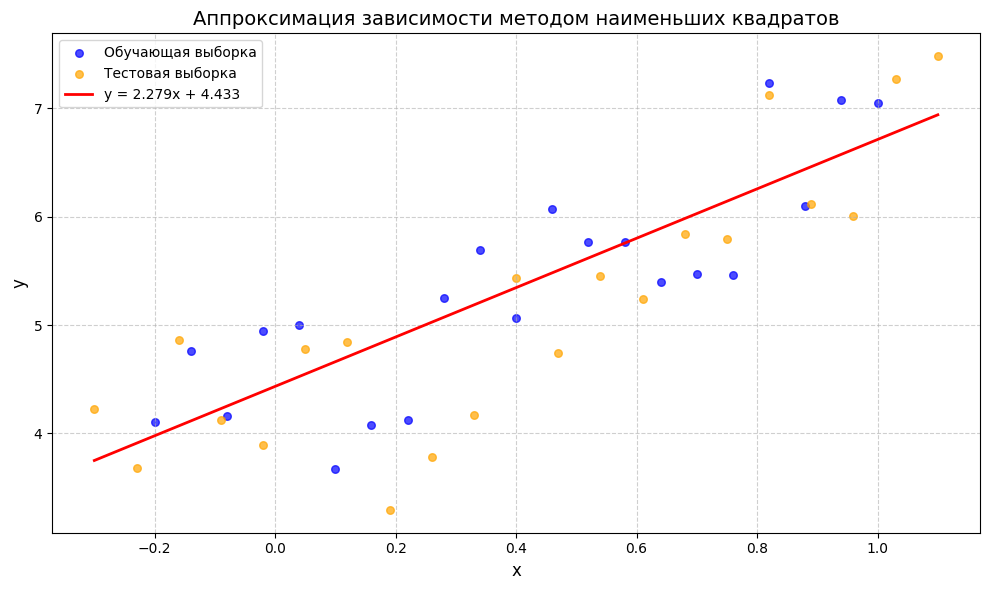

In [21]:
# ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
import numpy as np
import matplotlib.pyplot as plt

x_line = np.linspace(
    min(X_train.min(), X_test.min()),
    max(X_train.max(), X_test.max()),
    100
)
y_line = k * x_line + b

plt.figure(figsize=(10, 6))
plt.scatter(X_train, Y_train, color='blue',
            label='Обучающая выборка', alpha=0.7, s=30)
plt.scatter(X_test, Y_test, color='orange',
            label='Тестовая выборка', alpha=0.7, s=30)
plt.plot(x_line, y_line, color='red', linewidth=2,
         label=f'y = {k:.3f}x + {b:.3f}')

plt.xlabel('x', fontsize=12)
plt.ylabel('y', fontsize=12)
plt.title('Аппроксимация зависимости методом наименьших квадратов', fontsize=14)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**3. [0.15 балла]** Глядя на данные, подумайте, многочленом какой степени можно было бы лучше всего приблизить эту функцию с точки зрения минимизации среднеквадратичной ошибки на обучающей выборке. Найдите этот многочлен и напечатайте его в виде $a_0 + a_1 x + \ldots a_k x^k$. Для простоты кода можете использовать библиотеку [sympy](https://docs.sympy.org/latest/tutorials/intro-tutorial/index.html#intro-tutorial).

In [22]:
# ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
from sympy import symbols, expand

n = 11
X = np.vstack([X_train ** p for p in range(n)]).T
coefficients, *_ = np.linalg.lstsq(X, Y_train, rcond=None)

polynom = str(coefficients[0])
for i in range(1, n):
    polynom += " + (" + str(coefficients[i]) + ") * x^" + str(i)

print(polynom)

4.669172515342548 + (-2.159833307538153) * x^1 + (-36.175388924005254) * x^2 + (44.93560565090727) * x^3 + (1201.9528244189908) * x^4 + (-1660.826426306184) * x^5 + (-12969.927118750935) * x^6 + (46686.64428340412) * x^7 + (-63620.996377032556) * x^8 + (40177.53359025778) * x^9 + (-9818.57951849081) * x^10


**4. [0.1 балла]** Нарисуйте его график на одном чертеже вместе с точками $(x_i, y_i)$ из обеих выборок.

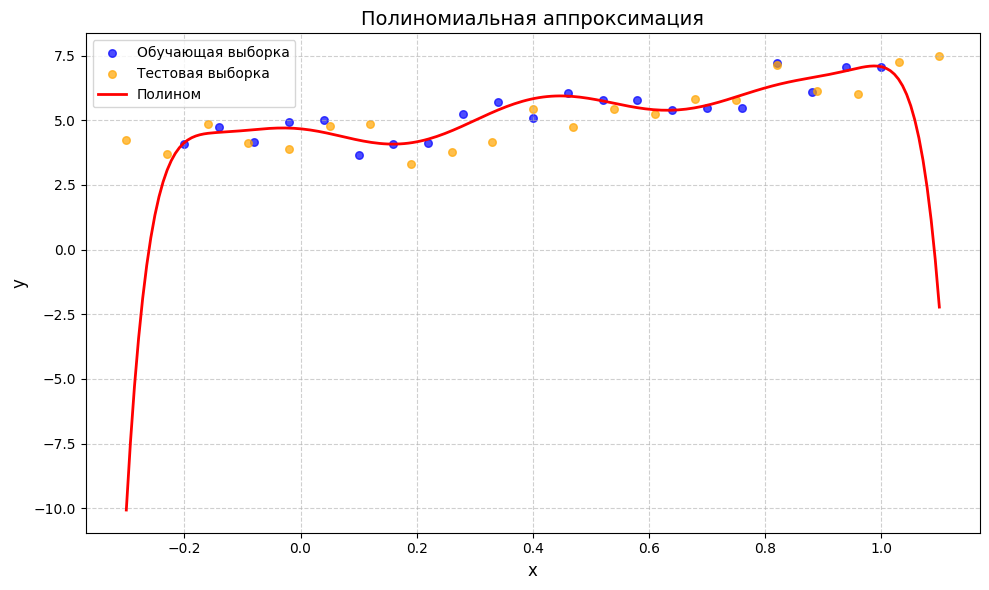

In [23]:
# ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
import numpy as np
import matplotlib.pyplot as plt
n = 11

X = np.vstack([X_train ** p for p in range(n)]).T
coefficients, *_ = np.linalg.lstsq(X, Y_train, rcond=None)

x_line = np.linspace(
    min(X_train.min(), X_test.min()),
    max(X_train.max(), X_test.max()),
    200
)

y_line = sum(coefficients[i] * x_line**i for i in range(n))
poly_str = " + ".join([f"{coefficients[i]:.3f}x^{i}" for i in range(n)])

plt.figure(figsize=(10, 6))

plt.scatter(X_train, Y_train,
            color='blue', label='Обучающая выборка',
            alpha=0.7, s=30)

plt.scatter(X_test, Y_test,
            color='orange', label='Тестовая выборка',
            alpha=0.7, s=30)

plt.plot(x_line, y_line,
         color='red', linewidth=2,
         label='Полином')

plt.xlabel('x', fontsize=12)
plt.ylabel('y', fontsize=12)
plt.title('Полиномиальная аппроксимация', fontsize=14)

plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

plt.show()

**5. [0.25 балла]** Для $k = 1,2,3,\ldots,10$ найдите многочлен $\hat{f_k}$ степени $k$, наилучшим образом приближающий неизвестную зависимость. Напечатайте найденные многочлены в виде $a_0 + a_1 x + \ldots a_k x^k$.

In [24]:
# ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
for k in range(1, 11):
    X = np.vstack([X_train ** p for p in range(k + 1)]).T
    coef, *_ = np.linalg.lstsq(X, Y_train, rcond=None)

    poly_str = f"f_{k}(x) = {coef[0]:.6f}"
    for i in range(1, k + 1):
        poly_str += f" + ({coef[i]:.6f})*x^{i}"

    print(poly_str)

f_1(x) = 4.433231 + (2.279134)*x^1
f_2(x) = 4.472477 + (1.157832)*x^1 + (1.401629)*x^2
f_3(x) = 4.460736 + (1.065016)*x^1 + (1.859751)*x^2 + (-0.381769)*x^3
f_4(x) = 4.341166 + (1.171802)*x^1 + (6.794092)*x^2 + (-13.051328)*x^3 + (7.918475)*x^4
f_5(x) = 4.431298 + (-0.130598)*x^1 + (3.274714)*x^2 + (21.374796)*x^3 + (-51.131481)*x^4 + (29.524978)*x^5
f_6(x) = 4.383795 + (-4.597179)*x^1 + (16.002904)*x^2 + (121.257097)*x^3 + (-481.510133)*x^4 + (581.453298)*x^5 + (-229.970133)*x^6
f_7(x) = 4.444513 + (-4.008896)*x^1 + (7.215459)*x^2 + (119.350784)*x^3 + (-314.231173)*x^4 + (122.878217)*x^5 + (238.699368)*x^6 + (-167.381965)*x^7
f_8(x) = 4.663789 + (-5.182774)*x^1 + (-26.695631)*x^2 + (268.860439)*x^3 + (109.895667)*x^4 + (-3132.856380)*x^5 + (6760.628443)*x^6 + (-5701.710172)*x^7 + (1729.477565)*x^8
f_9(x) = 4.645884 + (-4.552706)*x^1 + (-24.262717)*x^2 + (219.042038)*x^3 + (176.245411)*x^4 + (-2441.962689)*x^5 + (3913.268093)*x^6 + (-1216.448178)*x^7 + (-1522.098294)*x^8 + (903.215516)

**6. [1 балл]** Для каждого из них найдите среднеквадратическую ошибку на обучающих данных и на тестовых данных: $\frac1{n}\sum\limits_{i=1}^n\left( \hat{f_k}(x_i) - y_i \right)^2$ (в первом случае сумма ведётся по парам $(x_i, y_i)$ из обучающих данных, а во втором — по парам из тестовых данных).

In [25]:
# ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
for k in range(1, 11):
    X_tr = np.vstack([X_train ** p for p in range(k + 1)]).T
    X_te = np.vstack([X_test ** p for p in range(k + 1)]).T
    coef, *_ = np.linalg.lstsq(X_tr, Y_train, rcond=None)
    y_pred_train = X_tr @ coef
    y_pred_test = X_te @ coef
    mse_train = np.mean((Y_train - y_pred_train) ** 2)
    mse_test = np.mean((Y_test - y_pred_test) ** 2)

    print(f"k = {k}: train = {mse_train:.6f}, test = {mse_test:.6f}")

k = 1: train = 0.296897, test = 0.435120
k = 2: train = 0.269699, test = 0.356476
k = 3: train = 0.269497, test = 0.355346
k = 4: train = 0.261067, test = 0.441727
k = 5: train = 0.249985, test = 0.557973
k = 6: train = 0.188293, test = 2.581693
k = 7: train = 0.185396, test = 2.515783
k = 8: train = 0.159056, test = 4.357289
k = 9: train = 0.158472, test = 4.776342
k = 10: train = 0.153166, test = 14.632428


**7. [0.75 балла]** Для $k = 1,2,3,4,5,6$ нарисуйте графики полученных многочленов на одном чертеже вместе с точками $(x_i, y_i)$ из обеих выборок (возможно, график стоит сделать побольше; это делается командой `plt.figure(figsize=(width, height))`).

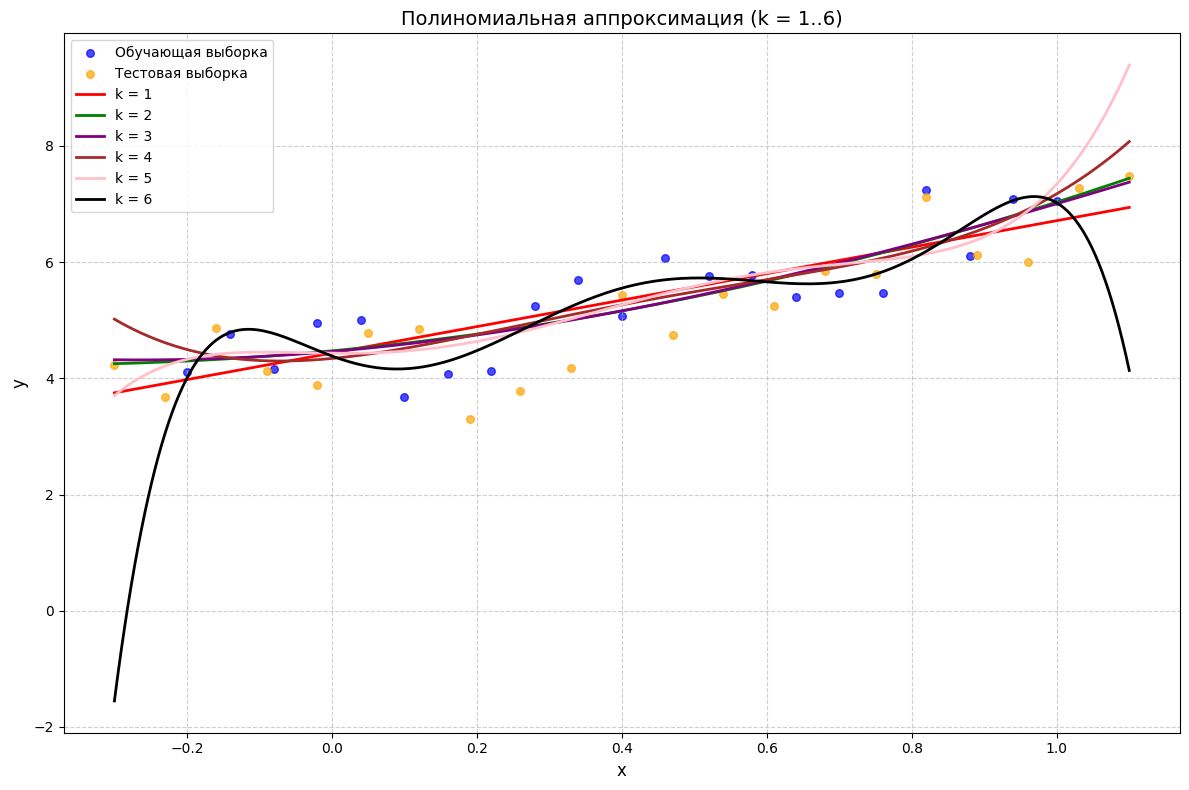

In [26]:
# ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
x_line = np.linspace(
    min(X_train.min(), X_test.min()),
    max(X_train.max(), X_test.max()),
    300
)

plt.figure(figsize=(12, 8))

plt.scatter(X_train, Y_train,
            color='blue', label='Обучающая выборка',
            alpha=0.7, s=30)

plt.scatter(X_test, Y_test,
            color='orange', label='Тестовая выборка',
            alpha=0.7, s=30)

colors = ['red', 'green', 'purple', 'brown', 'pink', 'black']

for k in range(1, 7):
    X = np.vstack([X_train ** p for p in range(k + 1)]).T
    coef, *_ = np.linalg.lstsq(X, Y_train, rcond=None)
    y_line = sum(coef[i] * x_line**i for i in range(k + 1))
    plt.plot(x_line, y_line,
             color=colors[k-1],
             linewidth=2,
             label=f'k = {k}')

plt.xlabel('x', fontsize=12)
plt.ylabel('y', fontsize=12)
plt.title('Полиномиальная аппроксимация (k = 1..6)', fontsize=14)

plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()

plt.show()

**8. [0.5 балла]** Что происходит с ошибкой при росте степени многочлена? Казалось бы, чем больше степень, тем более сложным будет многочлен и тем лучше он будет приближать нашу функцию. Подтверждают ли это ваши наблюдения? Как вам кажется, чем объясняется поведение ошибки на тестовых данных при $k = 10$? Как, по вашему мнению, в машинном обучении называется наблюдаемый вами эффект?

╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ При увеличении степени многочлена ошибка на обучающей выборке уменьшается. Это связано с тем, что модель становится более сложной и гибкой, и может всё точнее подгоняться под обучающие данные.

Однако на тестовой выборке поведение ошибки другое. Сначала, при увеличении степени, ошибка уменьшается, так как модель начинает лучше улавливать реальную зависимость в данных. Но после некоторого значения степени ошибка на тесте начинает расти. Это происходит потому, что модель становится слишком сложной и начинает подгоняться не только под закономерность, но и под шум в обучающих данных.

При k = 10 можно наблюдать, что многочлен сильно колеблется и принимает неестественную форму, стараясь пройти как можно ближе ко всем обучающим точкам. В результате он плохо обобщает на новые данные, и ошибка на тестовой выборке увеличивается.

Таким образом, хотя увеличение степени многочлена и позволяет лучше приближать обучающие данные, это не всегда приводит к улучшению качества на новых данных. Наблюдаемый эффект называется переобучением: модель слишком точно запоминает обучающую выборку и теряет способность к обобщению.


### Задание 2. Линейная регрессия (3.5 балла)

Скачайте файлы ``flats_moscow_mod.txt`` и ``flats_moscow_description.txt``. В первом из них содержатся данные о квартирах в Москве. Каждая строка содержит шесть характеристик некоторой квартиры, разделённые знаками табуляции; в первой строке записаны кодовые названия характеристик. Во втором файле приведены краткие описания признаков.

**0. [0 баллов]** Разделите выборку на обучающую и тестовую. Делать это лучше случайным образом (ведь вы не знаете, как создатели датасета упорядочили объекты); рекомендуем вам для этого функцию `sklearn.model_selection.train_test_split` с параметром `test_size=0.3`. Не забудьте зафиксировать параметр `random_state`.

In [27]:
# ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
from sklearn.model_selection import train_test_split
import pandas as pd
import numpy as np

data = pd.read_csv('/content/flats_moscow_mod.txt', sep='\t')

X = data[['totsp', 'livesp', 'kitsp', 'dist', 'metrdist']]
Y = data['price']

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.3, random_state=42
)

**1. [0.5 балла]** Вашей задачей будет построить с помощью метода наименьших квадратов (линейную) зависимость между ценой квартиры и остальными доступными параметрами. С помощью известных вам формул найдите регрессионные коэффициенты. Выпишите построенную модель.

In [28]:
# ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
X_train_np = np.c_[np.ones(len(X_train)), X_train]
beta = np.linalg.inv(X_train_np.T @ X_train_np) @ X_train_np.T @ Y_train

print("\nМодель:")
print(f"price = {beta[0]:.2f} + {beta[1]:.2f}*totsp + {beta[2]:.2f}*livesp + "
      f"{beta[3]:.2f}*kitsp + {beta[4]:.2f}*dist + {beta[5]:.2f}*metrdist")


Модель:
price = -8.10 + 1.59*totsp + 1.06*livesp + 2.07*kitsp + -3.41*dist + -1.39*metrdist


**2. [0.25 балла]** Какой смысл имеют их знаки? Согласуются ли они с вашими представлениями о жизни?

╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
Если знак положительный, то изменение характеристики прямо пропорционально изменению стоимости, если отрицательный - обратно пропорционально.
Положительные коэффициенты означают, что с увеличением этих характеристик цена квартиры растёт, что соответствует представлениям о жизни. Отрицательные коэффициенты показывают, что чем дальше квартира находится от центра города или от станции метро, тем ниже её стоимость, в целом, как и в жизни

**3. [0.25 балла]** Оцените качество приближения, вычислив среднеквадратическую ошибку на тестовой выборке.

In [29]:
# ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
X_test_np = np.c_[np.ones(len(X_test)), X_test]
Y_pred = X_test_np @ beta
mse = np.mean((Y_test - Y_pred) ** 2)

print("\nСреднеквадратическая ошибка на тестовой выборке:")
print(mse)


Среднеквадратическая ошибка на тестовой выборке:
1226.7814210409842


### Усложнение модели

Конечно, никто не гарантирует, что объясняемая переменная (цена квартиры) зависит от остальных характеристик именно линейно. Зависимость может быть, например, квадратичной или логарифмической; больше того, могут быть важны не только отдельные признаки, но и их комбинации. Это можно учитывать, добавляя в качестве дополнительных признаков разные функции от уже имеющихся характеристик: их квадраты, логарифмы, попарные произведения.

В этом задании вам нужно постараться улучшить качество модели, добавляя дополнительные признаки, являющиеся функциями от уже имеющихся. Но будьте осторожны: чрезмерное усложнение модели будет приводить к переобучению.

**4. [0.25 балла]** Опишите признаки, которые вы решили добавить. Объясните, чем был мотивирован выбор именно этих признаков.

╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ Можно добавить квадраты на totsp и dist, потому что зависимость цены от площади или расстояния может быть не совсем линейной.
Также логарифм от общей площади, так как цена обычно растёт не прямо пропорционально, а более плавно.
Ещё попарные произведения признаков, например totsp * metrdist, чтобы учесть, что признаки могут влиять на цену не только по отдельности, но и вместе.

**5. [2 балла]** Постройте с помощью метода наименьших квадратов (линейную) зависимость между ценой квартиры и новыми признаками. С помощью известных вам формул найдите регрессионные коэффициенты. Выпишите построенную модель.

In [30]:
# ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
data['totsp_sq'] = data['totsp'] ** 2
data['dist_sq'] = data['dist'] ** 2
data['log_totsp'] = np.log(data['totsp'])
data['totsp_metro'] = data['totsp'] * data['metrdist']

X = data[['totsp', 'livesp', 'kitsp', 'dist', 'metrdist',
          'totsp_sq', 'dist_sq', 'log_totsp', 'totsp_metro']]
Y = data['price']

X_train, X_test, Y_train, Y_test = train_test_split(
    X, Y, test_size=0.3, random_state=42
)
X_train_np = np.c_[np.ones(len(X_train)), X_train]
beta = np.linalg.inv(X_train_np.T @ X_train_np) @ X_train_np.T @ Y_train

print("\nМодель:")
print(f"price = {beta[0]:.2f} + {beta[1]:.2f}*totsp + {beta[2]:.2f}*livesp + "
      f"{beta[3]:.2f}*kitsp + {beta[4]:.2f}*dist + {beta[5]:.2f}*metrdist + "
      f"{beta[6]:.2f}*totsp^2 + {beta[7]:.2f}*dist^2 + "
      f"{beta[8]:.2f}*log(totsp) + {beta[9]:.2f}*(totsp*metrdist)")


Модель:
price = -817.34 + -7.87*totsp + 1.10*livesp + 2.58*kitsp + -5.27*dist + 0.06*metrdist + 0.03*totsp^2 + 0.09*dist^2 + 307.63*log(totsp) + -0.02*(totsp*metrdist)


**6. [0.25 балла]** Оцените качество приближения, вычислив среднеквадратическую ошибку на тестовой выборке.

In [14]:
# ╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
X_test_np = np.c_[np.ones(len(X_test)), X_test]
Y_pred = X_test_np @ beta
mse = np.mean((Y_test - Y_pred) ** 2)

print("\nСреднеквадратическая ошибка на тестовой выборке:")
print(mse)


Среднеквадратическая ошибка на тестовой выборке:
1109.9409790107634


### Задание 3. Регуляризация (3.5 балла)

Вспомним, что задача линейной регрессии формулируется как задача нахождения проекции вектора значений объясняемой переменной $y$ на линейную оболочку $\langle x_1,\ldots,x_k\rangle$ векторов значений регрессоров. Если векторы $x_1,\ldots,x_k$ линейно зависимы, то матрица $X^\top X$ вырожденна и задача не будет решаться с помощью приведённой выше формулы. В жизни, по счастью, различные признаки редко бывают *в точности* линейно зависимы, однако во многих ситуациях они скоррелированы и становятся "почти" линейно зависимыми. Таковы, к примеру, зарплата человека, его уровень образования, цена машины и суммарная площадь недвижимости, которой он владеет. В этом случае матрица $X^\top X$ будет близка к вырожденной, и это приводит к численной неустойчивости и плохому качеству решений; как следствие, будет иметь место переобучение. Один из симптомов этой проблемы — необычно большие по модулю компоненты вектора $a$.

Есть много способов борьбы с этим злом. Один из них — регуляризация. Сейчас мы рассмотрим одну из её разновидностей — **L2-регуляризацию**. Идея в том, чтобы подправить матрицу $X^\top X$, сделав её "получше". Например, это можно сделать, заменив её на $(X^\top X + \lambda E)$, где $\lambda > 0$ — некоторый скаляр. Пожертвовав точностью на обучающей выборке, мы тем не менее получаем численно более стабильное псевдорешение $a = (X^\top X + \lambda E)^{-1}X^\top y$ и снижаем эффект переобучения. *Гиперпараметр* $\lambda$ нужно подбирать, и каких-то универсальных способов это делать нет, но зачастую можно его подобрать таким, чтобы ошибка на тестовой выборке падала.

Однако есть некоторые правила, которых стоит придерживаться при подборе коэффициента регуляризации. Обычно в такой ситуации всю выборку делят на три части: обучающую, *валидационную* и тестовую. Сначала по валидационной подбирают значение гиперпараметра, потом по обучающей строят модель, а по тестовой оценивают её итоговое качество. Кроме того, подбирать $\lambda$ нужно по логарифметической сетке, чтобы узнать оптимальный порядок величины.

**1. [0.25 балла]** Почему не стоит подбирать коэффициент регуляризации по обучающей выборке? По тестовой выборке?

╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ Если подбирать коэффициент регуляризации по обучающей выборке, то модель будет подстраиваться под те же данные, на которых она обучается. В таком случае мы фактически подгоняем парметр под ответы, это приводит к переобучению
Если подбирать λ по тестовой выборке, то мы нарушаем саму идею тестирования. Тестовая выборка должна использоваться только для финальной оценки. Если мы начинаем подбирать по ней гиперпараметры, то она перестаёт быть независимой, и оценка качества становится смещённой. По сути, мы снова начинаем переобучаться, но уже на тестовые данные.

**2. [0 баллов]** Теперь давайте вспомним первую задачу. Если вы её сделали, то помните, что ошибка аппроксимации многочленом шестой степени довольно высокая. Попытаемся использовать регуляризацию при построении модели. Поделите обучающую выборку из первой задачи на две части, одну из которых объявите обучающей, а другую — валидационной (будьте осторожны при выборе `train_size`, в этой выборке не так много данных).

In [36]:
from sklearn.model_selection import train_test_split

X_train = data_train[:, 0]
Y_train = data_train[:, 1]
X_test = data_test[:, 0]
Y_test = data_test[:, 1]

degree = 6
X_poly_train = np.vstack([X_train ** p for p in range(degree + 1)]).T
X_poly_test = np.vstack([X_test ** p for p in range(degree + 1)]).T

X_train_reg, X_val_reg, y_train_reg, y_val_reg = train_test_split(
    X_poly_train, Y_train, train_size=0.8, random_state=67
)

**3. [0.75 балла]** Убедитесь, что, используя регуляризацию с хорошо подобранным коэффициентом $\lambda$, ошибку на тестовой выборке можно сделать не больше, чем для многочлена оптимальной степени в модели без регуляризации.

In [37]:
lambdas = np.logspace(-4, 4, 50)

best_lambda = None
min_val_mse = float('inf')
E = np.eye(X_train_reg.shape[1])

for lam in lambdas:
    a_lam = np.linalg.inv(X_train_reg.T @ X_train_reg +
                          lam * E) @ X_train_reg.T @ y_train_reg
    val_pred = X_val_reg @ a_lam
    val_mse = np.mean((val_pred - y_val_reg) ** 2)
    if val_mse < min_val_mse:
        min_val_mse = val_mse
        best_lambda = lam

print("Лучшее lambda:", best_lambda)

E_full = np.eye(X_poly_train.shape[1])
a_best = np.linalg.inv(X_poly_train.T @ X_poly_train +
                       best_lambda * E_full) @ X_poly_train.T @ Y_train

test_pred_reg = X_poly_test @ a_best
mse_test_reg = np.mean((test_pred_reg - Y_test) ** 2)
print("MSE на тесте (с регуляризацией, степень 6):", mse_test_reg)

a_noreg = np.linalg.lstsq(X_poly_train, Y_train, rcond=None)[0]
test_pred_noreg = X_poly_test @ a_noreg
mse_noreg = np.mean((test_pred_noreg - Y_test) ** 2)
print("MSE на тесте (без регуляризации, степень 6):", mse_noreg)

best_mse_allk = float('inf')
best_k = 1
for k in range(1, 11):
    X_k = np.vstack([X_train ** p for p in range(k + 1)]).T
    X_k_test = np.vstack([X_test ** p for p in range(k + 1)]).T
    c, *_ = np.linalg.lstsq(X_k, Y_train, rcond=None)
    mse_k = np.mean((X_k_test @ c - Y_test) ** 2)
    if mse_k < best_mse_allk:
        best_mse_allk = mse_k
        best_k = k
print(
    f"MSE на тесте (лучшая степень {best_k} без регуляризации):", best_mse_allk)

Лучшее lambda: 0.0062505519252739694
MSE на тесте (с регуляризацией, степень 6): 0.3819191754026457
MSE на тесте (без регуляризации, степень 6): 2.581692933697309
MSE на тесте (лучшая степень 3 без регуляризации): 0.3553464571518425


**4. [0.25 балла]** Для этого $\lambda$ сравните $\det(X^\top X)$ и $\det(X^\top X + \lambda E)$. Теоретически объясните полученный результат, доказав, что $\det(X^\top X+\lambda E) > 0$ при $\lambda>0$.

╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ

При подстановке найденного λ оказывается, что $\det(X^\top X + λ E) > \det(X^\top X)$.

Матрица $(X^\top X)$ является неотрицательно определённой, но среди ее значений могут быть нули (если признаки линейно зависимы). Поэтому её определитель может быть равен нулю.
При добавлении λE мы увеличиваются все собственные значения на λ > 0. То есть если раньше собственные значения были μi ≥ 0, то теперь они становятся μi + λ > 0.

Так как определитель равен произведению собственных значений, получаем: $$\det(X^\top X + λ E) = \prod_{i=1}^k (μi + λ)$$

И поскольку все μi + λ > 0, то их произведение строго положительно: $\det(X^\top X + λ E)$ > 0. Таким образом, добавление регуляризации делает матрицу невырожденной и гарантирует, что решение существует и единственно.

**5. [0.25 балла]** Нарисуйте на одном чертеже графики многочленов шестой степени, приближающих неизвестную функцию, для модели с регуляризацией и без.

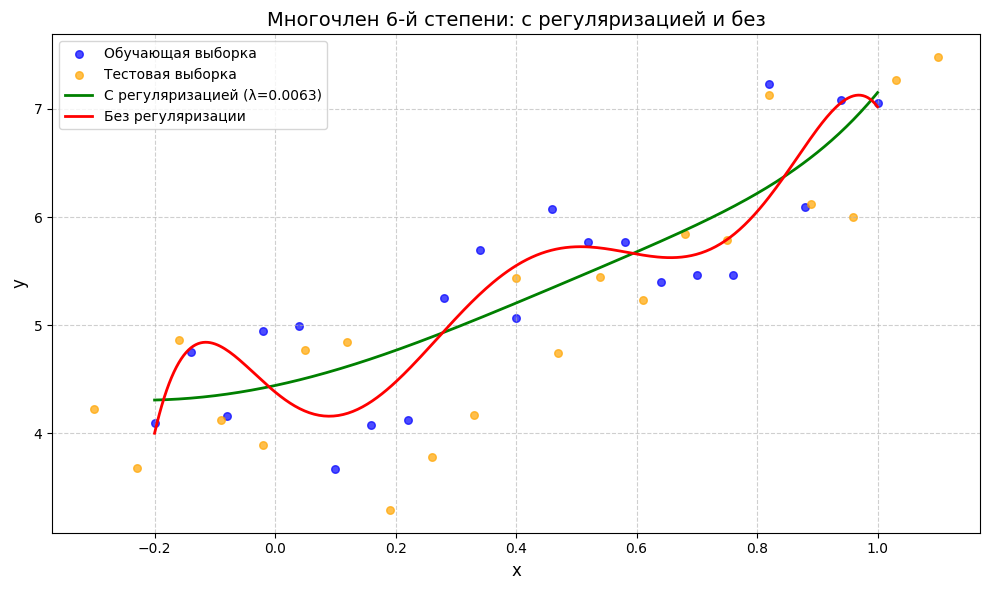

In [38]:
import matplotlib.pyplot as plt

x_line = np.linspace(X_train.min(), X_train.max(), 300)
X_line = np.vstack([x_line ** p for p in range(degree + 1)]).T

y_line_reg = X_line @ a_best
y_line_noreg = X_line @ a_noreg

plt.figure(figsize=(10, 6))
plt.scatter(X_train, Y_train, color='blue',
            label='Обучающая выборка', alpha=0.7, s=30)
plt.scatter(X_test, Y_test, color='orange',
            label='Тестовая выборка', alpha=0.7, s=30)
plt.plot(x_line, y_line_reg, color='green', linewidth=2,
         label=f'С регуляризацией (λ={best_lambda:.4f})')
plt.plot(x_line, y_line_noreg, color='red',
         linewidth=2, label='Без регуляризации')
plt.xlabel('x', fontsize=12)
plt.ylabel('y', fontsize=12)
plt.title('Многочлен 6-й степени: с регуляризацией и без', fontsize=14)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

**6. [0.25 балла]** Чем первый из них выгодно отличается от второго?

╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ
Многочлен с регуляризацией получается более гладким, потому что регуляризация не даёт коэффициентам становиться слишком большими, из-за этого график не начинает сильно «прыгать» между точками. В итоге модель лучше отражает общую зависимость и не подгоняется под случайный шум в данных.

А без регуляризации коэффициенты могут получаться очень большими, из-за этого график сильно колеблется.


**7. [0.75 балла]** Пусть заданы $X\in \text{Mat}_{n \times k}(\mathbb{R})$ ($k \leqslant n$), $y \in \mathbb{R}^n$, $\lambda \geqslant 0$, а также известно, что $\text{rk}~X = k$. Решите теоретически следующую задачу оптимизации:
$$|Xa - y|^2 + \lambda|a|^2\rightarrow\min\limits_{a \in \mathbb{R}^k}.$$
(То есть найдите все векторы $a \in \mathbb{R}^k$, для которых выражение слева принимает наименьшее возможное значение.) В частности, докажите существование решений и укажите их количество в зависимости от входных данных.

╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ

Запишем целевую функцию в явном виде:
$$f(a) = |Xa - y|^2 + \lambda|a|^2 = (Xa - y)^\top(Xa - y) + \lambda a^\top a = a^\top(X^\top X + \lambda E)a - 2(X^\top y)^\top a + |y|^2.$$

**Случай $\lambda > 0$.** Матрица $X^\top X + \lambda E$ положительно определена. Поэтому функция $f$ строго выпукла, и у неё существует единственный минимум. Он достигается в точке, где градиент равен нулю:
$$\nabla f(a) = 2(X^\top X + \lambda E)a - 2X^\top y = 0 \implies (X^\top X + \lambda E)a = X^\top y.$$
Так как $X^\top X + \lambda E$ обратима, решение единственно:
$$\hat{a} = (X^\top X + \lambda E)^{-1}X^\top y.$$

**Случай $\lambda = 0$.** Задача превращается в обычный МНК. Условие $\mathrm{rk}\,X = k$ означает, что $X^\top X$ обратима, и единственное решение то же:
$$\hat{a} = (X^\top X)^{-1}X^\top y.$$

**Вывод.** При любом $\lambda \geq 0$ и $\mathrm{rk}\,X = k$ решение существует и единственно.

Интуитивно это можно понимать так: мы ищем компромисс между минимизацией длины разности $|Xa - y|$ (то есть точностью решения задачи регрессии) и тем, чтобы компоненты вектора $a$ не становились слишком большими по модулю.

**8. [0.25 балла]** Попробуйте объяснить, почему регуляризовать (штрафовать за слишком большую абсолютную величину) коэффициент при константном признаке (который состоит из одних единиц) — плохая идея.

╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ

Константный признак отвечает за свободный член, то есть просто сдвигает все предсказания вверх или вниз. Его значение зависит от среднего уровня цены, а не от сложности модели.

Если его тоже штрафовать, то мы будем тянуть его к нулю, предполагая, что данные проходят через начало координат, что обычно неправильно. Из-за этого предсказания могут смещаться и становиться хуже.

Поэтому регуляризацию применяют к остальным коэффициентам, чтобы ограничить сложность модели, а свободный член не трогают, потому что он на сложность не влияет.


**9. [0.5 балла]** Пусть теперь $\text{rk}~X < k$. Всегда ли в этом случае существует решение? Если существует, то является ли оно единственным? Ответ обоснуйте.

╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ

**При $\lambda > 0$:** матрица $X^\top X + \lambda E$ положительно определена вне зависимости от ранга $X$. Следовательно, она обратима и уравнение $(X^\top X + \lambda E)a = X^\top y$ имеет единственное решение $\hat{a} = (X^\top X + \lambda E)^{-1}X^\top y$. Таким образом, при $\lambda > 0$ решение всегда существует и единственно, даже если $\mathrm{rk}\,X < k$.

**При $\lambda = 0$:** матрица $X^\top X$ вырождена, поэтому у неё нетривиальное ядро. Уравнение $X^\top X a = X^\top y$ тем не менее всегда совместно, так как $X^\top y \in \mathrm{Im}(X^\top X)$ . Поскольку ядро ненулевое, решений бесконечно много: если $a_0$ — одно из них, то $a_0 + v$ тоже является решением для любого $v \in \ker(X)$.

**10. [0.25 балла]** Покажите теоретически, что если решений бесконечно много, то среди них обязательно найдутся решения со сколь угодно большими по модулю компонентами вектора $a$. Почему большие веса в линейной модели — плохо?

╰( ͡° ͜ʖ ͡° )つ──☆*:・ﾟ

Если решений бесконечно много, то $\ker(X) \neq \{0\}$, то есть существует вектор $v \neq 0$ такой, что $Xv = 0$. Пусть $a_0$ — одно из решений задачи. Тогда для любого $t \in \mathbb{R}$ вектор $a_t = a_0 + tv$ тоже является решением:
$$|Xa_t - y|^2 = |X(a_0 + tv) - y|^2 = |Xa_0 + tXv - y|^2 = |Xa_0 - y|^2.$$
При $t \to \infty$ имеем $|a_t| \to \infty$, то есть среди решений есть векторы со сколь угодно большой нормой.

Линейная модель с большими весами крайне чувствительна к малым изменениям входных признаков: небольшая погрешность в измерении $x$ приводит к большому изменению предсказания $\hat{y} = a^\top x$. Такая модель запоминает шум в обучающих данных, а не реальную закономерность, и даёт плохие предсказания на новых данных — это переобучение.

### Задание 4. Онлайн-обучение линейной регрессии (3 балла)

Раньше мы работали в ситуации, когда объекты $x_i$ и значения $y_i$ даны с самого начала и всегда доступны. Допустим теперь, что пары $(x_i, y_i)$ поступают к нам по одной и мы не можем себе позволить хранить их все в памяти (это может быть актуально, например, если вы пытаетесь обучить модель на устройстве со сравнительно небольшим количеством оперативной памяти: скажем, на мобильном телефоне или на бортовом компьютере спутника связи). В этом случае нам нужно уметь решать следующую задачу:

**Известно:** решение задачи регрессии для датасета $(x_1, y_1),\ldots,(x_t,y_t)$;

**На вход поступает:** новая пара $(x_{t+1}, y_{t+1})$;

**Требуется:** быстро (за время, не зависящее от $t$) отыскать решение задачи регрессии для расширенного датасета $(x_1, y_1),\ldots,(x_t,y_t),(x_{t+1}, y_{t+1})$.

Обозначим $X_{(t)} = (x_1\ldots x_t)^\top$ и $y_{(t)} = (y_1,\ldots,y_t)^\top$. Тогда, как мы хорошо помним, решение задачи регрессии для датасета $(x_1, y_1),\ldots,(x_t,y_t)$ имеет вид $\hat{a}_{(t)} = \left(X^\top_{(t)}X_{(t)}\right)^{-1}X^\top_{(t)}y_{(t)}$. Размеры матриц $X^\top_{(t)}X_{(t)}$ и $X^\top_{(t)}y_{(t)}$ не зависят от $t$, поэтому их мы, пожалуй, можем себе позволить хранить в памяти.

**1. [1 балл]** И вот ваше первое задание в этом разделе: придумайте алгоритм, принимающий на вход матрицы $X^\top_{(t)}X_{(t)}$ и $X^\top_{(t)}y_{(t)}$, а также пару $(x_{t+1}, y_{t+1})$, и вычисляющий матрицы $X^\top_{(t+1)}X_{(t+1)}$ и $X^\top_{(t+1)}y_{(t+1)}$. Сложность вашего алгоритма не должна зависеть от $t$. Опишите ваш алгоритм теоретически и обоснуйте его сложность.


Заметим, что при добавлении новой пары $(x_{t+1}, y_{t+1})$ матрица $X_{(t+1)}$ получается из $X_{(t)}$ дописыванием строки $x_{t+1}^\top$ снизу. Тогда:

$$X_{(t+1)}^\top X_{(t+1)} = \sum_{i=1}^{t+1} x_i x_i^\top = X_{(t)}^\top X_{(t)} + x_{t+1} x_{t+1}^\top$$

$$X_{(t+1)}^\top y_{(t+1)} = \sum_{i=1}^{t+1} x_i y_i = X_{(t)}^\top y_{(t)} + x_{t+1} y_{t+1}$$

Таким образом, алгоритм такой:
1. Вычислить $x_{t+1} x_{t+1}^\top$ — матрицу ранга 1 размера $k \times k$.
2. Прибавить её к $X_{(t)}^\top X_{(t)}$.
3. Прибавить $x_{t+1} y_{t+1}$ к вектору $X_{(t)}^\top y_{(t)}$.
4. Найти $\hat{a}_{(t+1)} = \left(X_{(t+1)}^\top X_{(t+1)}\right)^{-1} X_{(t+1)}^\top y_{(t+1)}$.

Шаги 1–3 требуют $O(k^2)$ операций, что не зависит от $t$. Шаг 4 стоит $O(k^3)$, но размер $k$ фиксирован. Итого сложность каждого обновления — $O(k^3)$, не зависит от $t$.

**2. [2 балла]** Теперь настало время написать немного кода и порисовать красивые картинки. Вам нужно будет реализовать симуляцию онлайн-обучения регрессии для задачи приближения функции (в данном случае $f_{\text{true}}(x) = 2x\sin(5x) + x^2 - 1$; все значения искажены небольшим нормальным шумом) многочленом степени не выше 5.

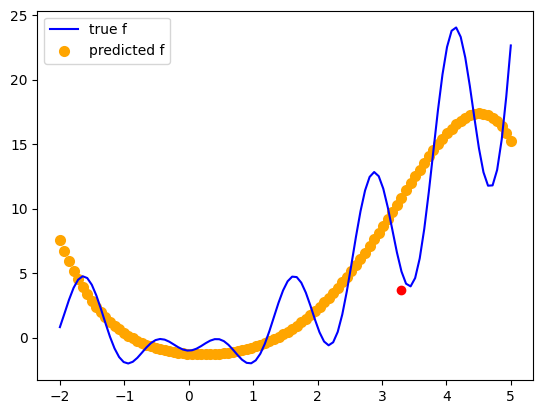

In [40]:
from IPython.display import clear_output


def f_true(x): return 2*x*np.sin(5*x) + x**2 - 1

x_grid = np.linspace(-2, 5, 100)
x_grid_enl = np.hstack([x_grid.reshape((100, 1))**j for j in range(6)])
y_grid = f_true(x_grid)

XtX = np.zeros((6, 6))
Xty = np.zeros(6)

for i in range(200):

    x_new = np.random.uniform(-2, 5)
    y_new = f_true(x_new) + 2*np.random.randn()

    x_feat = np.array([x_new**j for j in range(6)])
    XtX += np.outer(x_feat, x_feat)
    Xty += x_feat * y_new

    if (i+1) % 5 == 0:
        clear_output(True)
        plt.plot(x_grid, y_grid, color='blue', label='true f')
        plt.scatter(x_new, y_new, color='red')

        a_hat = np.linalg.solve(XtX + 1e-8 * np.eye(6), Xty)

        y_pred = x_grid_enl @ a_hat

        plt.scatter(x_grid, y_pred, color='orange',
                    linewidth=2, label='predicted f')

        plt.legend(loc='upper left')
        plt.show()

### Добавление. QR-разложение

**QR-разложением** матрицы $A$ (не обязательно квадратной) мы будем называть её представление в виде $A = QR$, где $Q$ — матрица с ортонормированными столбцами, а $R$ — верхнетреугольная матрица.

Смысл QR-разложения следующий. Пусть $a_1,\ldots,a_m$ — столбцы матрицы $A$, $q_1,\ldots,q_t$ — столбцы матрицы $Q$. Тогда $q_1,\ldots,q_t$ — это ортонормированный базис в подпространстве, являющемся линейной оболочкой векторов $a_1,\ldots,a_m$, а в матрице $R$ записаны коэффициенты, с помощью которых $a_i$ выражаются через $q_1,\ldots,q_t$.

Находить QR-разложение заданной матрицы можно разными способами. Мы познакомим вас не с самым лучшим из них, но по крайней мере с наиболее простым концептуально. Заметим, что ортогональный базис линейной оболочки можно найти с помощью ортогонализации Грама-Шмидта. При этом коэффициенты из матрицы $R$ получаются в качестве побочного продукта этого процесса:

```python
for j = 1...n:
    q_j = a_j
    for i = 1,...,j-1:
        r_ij = (q_i, a_j)
        q_j = q_j - r_ij * q_i
    r_jj = |q_j|
    if r_jj == 0: # a_j in <a_1,...,a_j-1>
        # What would you do in this case?..
    q_j = q_j / r_jj
```

Для нахождения QR-разложения вы можете использовать библиотечную функцию `scipy.linalg.qr`.

Поскольку лабораторная про линейную регрессию, не так-то просто замять вопрос о том, какое же отношение QR-разложение имеет к задаче регрессии. Упомянем одно из возможных применений.

Допустим, мы нашли QR-разложение матрицы $X$, а именно: $X = QR$. Тогда
$$X^\top X = (QR)^\top (QR) = R^\top Q^\top QR = R^\top R$$

Поскольку в задаче регрессии матрица $X$ обычного полного ранга (то есть её столбцы линейно независимы), матрица $R$ будет квадратной. Благодаря этому нашу обычную формулу для набора регрессионных коэффициентов $\hat{a}$ можно переписать в следующем виде:

$$\hat{a} = (X^TX)^{-1}X^Ty = (R^TR)^{-1}(QR)^Ty = R^{-1}(R^T)^{-1}R^TQ^Ty = R^{-1}Q^Ty$$

Как видите, формула стала проще. Более того, зачастую обращение матрицы $R$ может быть численно более устойчиво, чем обращение матрицы $X^TX$.